# 01 · Image operations & plotting  (⏱ ~60 min)

**Goal:** manipulate images (resample, smooth, threshold, do math) and visualise them well. Plotting is what you'll use most in papers, reports and sanity checks.

**Concepts**
- *Space matters*: images only line up if they share an affine + shape. `resample_to_img` fixes that.
- *Smoothing* (`smooth_img`, FWHM in mm) trades resolution for signal-to-noise.
- *Stat maps vs anatomical vs EPI*: nilearn has `plot_anat`, `plot_epi`, `plot_stat_map`, `plot_roi`, `plot_glass_brain`, plus interactive `view_img`.

**Gallery to read afterwards:** `examples/01_plotting` and `examples/06_manipulating_images`.

In [1]:
!pip install -q nilearn
import nilearn, numpy as np, pandas as pd, matplotlib.pyplot as plt
print("nilearn", nilearn.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 73.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 78.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
nilearn 0.14.1


In [12]:
from nilearn import datasets, image, plotting
haxby = datasets.fetch_haxby(subjects=[2])
atlas = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
print(atlas.keys())

[fetch_haxby] Dataset directory found: /root/nilearn_data/haxby2001

[fetch_atlas_harvard_oxford] Dataset directory found: /root/nilearn_data/fsl

dict_keys(['maps', 'labels', 'description', 'lut', 'atlas_type', 'template', 'filename'])


## Exercises
- **Ex 1.** Make the mean functional image and display it with `plotting.plot_epi`. Then put the anatomical in the background with `plotting.plot_anat`. What's different about the two images' resolutions?
- **Ex 2.** Smooth the mean image with `image.smooth_img` at 4 mm and 8 mm FWHM and plot all three side by side (use `axes=` or `matplotlib` subplots). *Predict*: what happens to the peak values?
- **Ex 3.** Use `image.math_img` to build a "stat map": e.g. z-score the mean image (`"(img - np.mean(img)) / np.std(img)"`). Plot it with `plot_stat_map` using `threshold=` and `bg_img=`. Why do we need a threshold on stat maps?
- **Ex 4.** The atlas lives in a different space/resolution to the functional data. Use `image.resample_to_img(..., interpolation="nearest")` to bring it into functional space. **Why nearest and not continuous interpolation for label images?**
- **Ex 5.** Plot the atlas with `plotting.plot_roi` over the anatomical. Then extract just one region (e.g. find the index of "Precentral Gyrus" in `atlas.labels`, and use `math_img` or `image.new_img_like`) and plot it.
- **Ex 6 (stretch).** Try `plotting.view_img` (interactive) and `plotting.plot_glass_brain`. In a sentence, when would you pick each?
- **Ex 7 (stretch).** Project a volume onto the cortical surface. Nilearn now has a `surface.SurfaceImage` class: look at `datasets.load_fsaverage()` for the meshes, `SurfaceImage.from_volume(...)`, and `plotting.plot_surf_stat_map`. (The older `surface.vol_to_surf` still exists underneath; compare what each returns.)

## Gallery to compare with, after your own attempt
`01_plotting`: `plot_atlas.py`, `plot_overlay.py`, `plot_demo_plotting.py`, `plot_demo_glass_brain.py`, `plot_3d_map_to_surface_projection.py`
`06_manipulating_images`: `plot_smooth_mean_image.py`, `plot_resample_to_template.py`, `plot_threshold_image.py`, `plot_negate_image.py`
`00_tutorials`: `plot_surface_101.py` (surface basics)

In [16]:
# Ex 1
haxby_func_image = image.load_img(haxby['func'])
haxby_anat_image = image.load_img(haxby['anat'])

atlas_func_image = image.load_img(atlas['maps'])


In [33]:
print(nilearn.image.index_img(haxby_func_image,1).shape)
print(atlas_func_image.shape)
#Seems like the atlas data set is has finer resolution

(40, 64, 64)
(91, 109, 91)


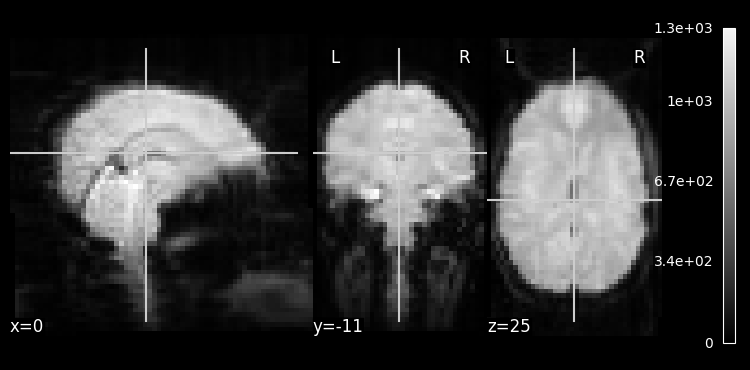

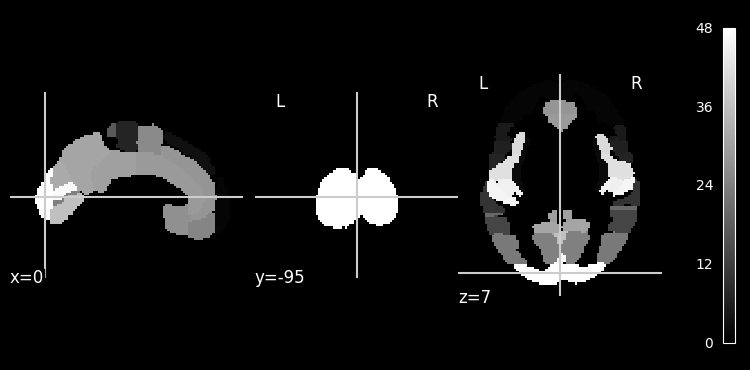

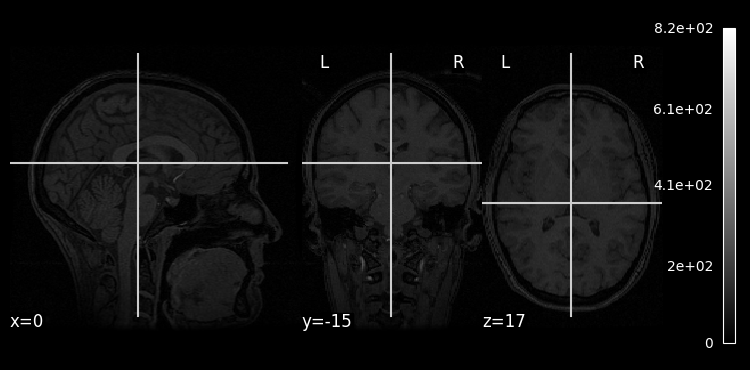

In [24]:
nilearn.plotting.plot_epi(nilearn.image.index_img(haxby_func_image,1))
nilearn.plotting.plot_epi(atlas_func_image)
nilearn.plotting.plot_anat(haxby_anat_image)

In [37]:
# Ex 2

#Floor values will likely be brought up and peak values brought down.
#TODO Why would someone want to smooth an image when you seemingly lose so much resolution?

mean_img = image.mean_img(haxby_func_image)
smooth_img_4 = image.smooth_img(mean_img,4)
smooth_img_8 = image.smooth_img(mean_img,8)

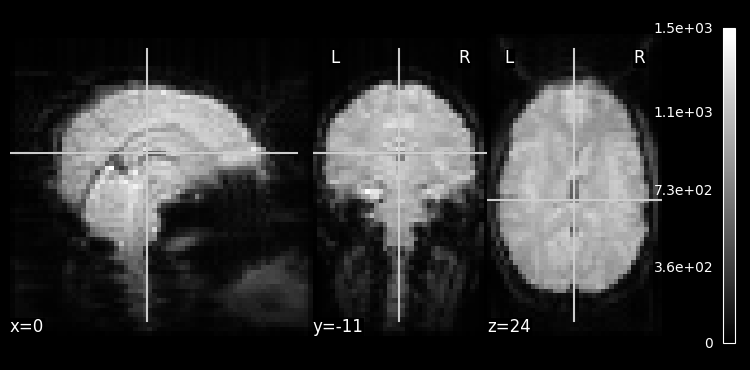

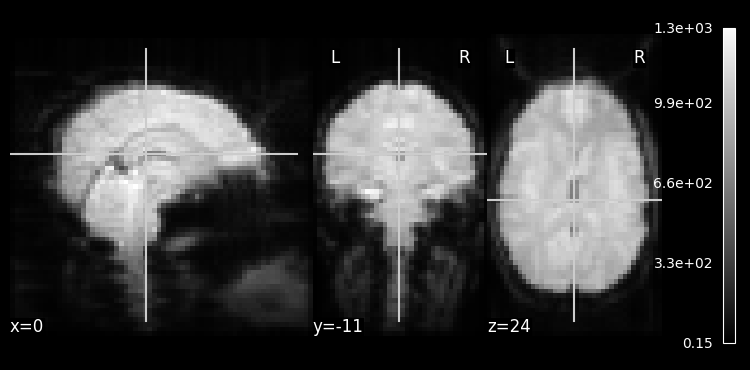

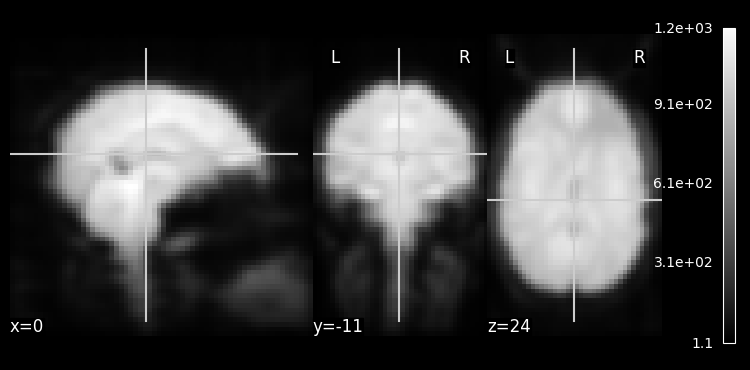

In [39]:
nilearn.plotting.plot_epi(mean_img)
nilearn.plotting.plot_epi(smooth_img_4)
nilearn.plotting.plot_epi(smooth_img_8)

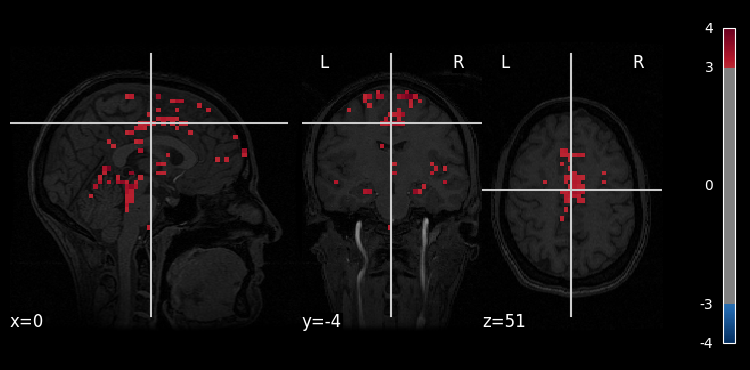

In [40]:
# Ex 3
stat_map = nilearn.image.math_img("(img - np.mean(img)) / np.std(img)", img=mean_img)
nilearn.plotting.plot_stat_map(stat_map, bg_img=haxby_anat_image, threshold=3)
#A threshhold is needed because otherwise, everything would light up

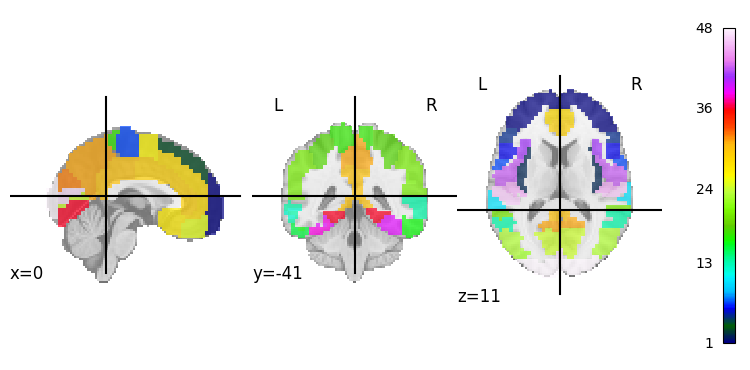

In [43]:
# Ex 4
atlas_resampled = image.resample_to_img(atlas_func_image, haxby_func_image, interpolation="nearest")
nilearn.plotting.plot_roi(atlas_resampled)
# Here, Atlas is a list of labeled regions. if we used continuous or linear, we would get values/labels that don't exist (e.g. 3.5 or 7.2)

Ex 5. Plot the atlas with plotting.plot_roi over the anatomical. Then extract just one region (e.g. find the index of "Precentral Gyrus" in atlas.labels, and use math_img or image.new_img_like) and plot it.

In [54]:
atlas.labels.index('Precentral Gyrus')
#

7

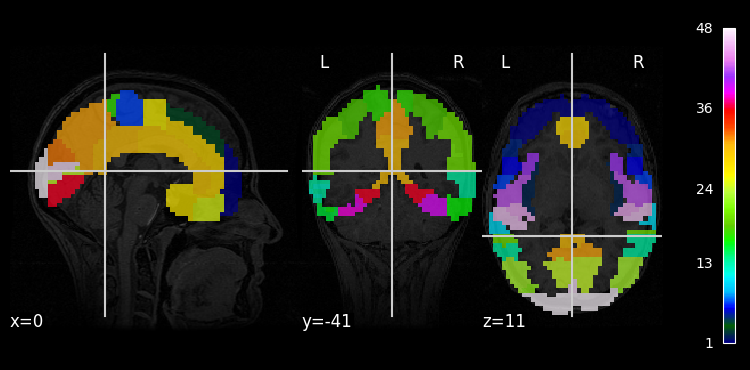

In [44]:
# Ex 5

nilearn.plotting.plot_roi(atlas_resampled, bg_img=haxby_anat_image)

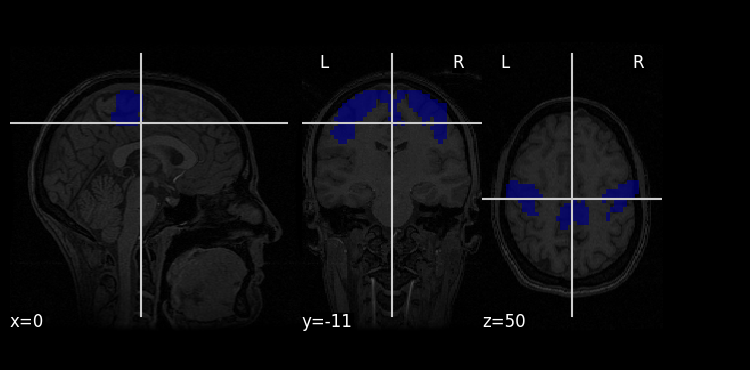

In [66]:
raw_np = np.array(atlas_resampled.get_fdata())
gyrus_np = np.zeros(raw_np.shape)
gyrus_np[raw_np==7] = 1
just_gyrus = nilearn.image.new_img_like(atlas_resampled, gyrus_np)

nilearn.plotting.plot_roi(just_gyrus, bg_img=haxby_anat_image)

## Check your understanding
- What two things must match for two images to be voxel-wise comparable?  
A: The array shape and the affine must align.
- What would go wrong if you smoothed *before* resampling a label atlas? (Or smoothed a label atlas at all?)  
A: You'd get values corresponding to labels that don't/can't exist (i.e. 7.2)

## Industry/research angle
Figure generation for papers, QC reports across hundreds of subjects, and clinical-trial imaging dashboards all rely on exactly these plotting + resampling steps.